# E1: CNN | 64 Mel bins | không SpecAugment
Nhánh GitHub: `04-E1-cnn-mel64`

Learning rate chọn trên fold 1 (chỉ dùng validation), sau đó chạy 5 fold (3 train, 1 validation, 1 test) và kiểm tra nhiễu Gaussian SNR 20/10/0 dB. Chạy lại ô sẽ tiếp tục từ fold còn dở.

In [7]:
!pip -q install soundfile
from google.colab import drive
drive.mount('/content/drive')
import sys
sys.path.append('/content/drive/MyDrive/ESC50')
from esc_lib import *
setup()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
GPU: Tesla T4 | VRAM 15.6 GB | torch 2.14.1+cu130 | CUDA 13.0
RAM trống 11.7 GB | ổ đĩa trống 120.8 GB
Mixup: BẬT | quick: False | kết quả lưu ở: /content/drive/MyDrive/ESC50/results_mixup


In [8]:
EXP_ID = "E1"
print(EXPERIMENTS[EXP_ID])
meta, X, X_DEV, y, folds = load_data()

{'model': 'cnn', 'n_mels': 64, 'specaug': False}


  0%|          | 0/2000 [00:00<?, ?it/s]

X: (2000, 110250) | y: (2000,) | nằm trên: cuda:0


## Tìm learning rate (fold 1)

In [9]:
lr = search_lr(EXP_ID)

train:   0%|          | 0/40 [00:00<?, ?it/s]

E1 {'LR': 0.0003, 'EPOCHS': 40} -> 0.7996


train:   0%|          | 0/40 [00:00<?, ?it/s]

E1 {'LR': 0.001, 'EPOCHS': 40} -> 0.787


,LR,EPOCHS,val_macro_f1,best_epoch
0,0.0003,40,0.799570,40
1,0.0010,40,0.786963,31


E1: learning rate được chọn = 0.0003


## Chạy 5 fold và kiểm tra độ bền với nhiễu

In [10]:
runs, rob = run_exp(EXP_ID, lr)

E1 | fold 1:   0%|          | 0/80 [00:00<?, ?it/s]

[E1 | fold 1] acc 0.8125 | macro-F1 0.8056 | lr 0.0003 | epoch tốt nhất 70 | 94s


E1 | fold 2:   0%|          | 0/80 [00:00<?, ?it/s]

[E1 | fold 2] acc 0.8375 | macro-F1 0.8309 | lr 0.0003 | epoch tốt nhất 68 | 94s


E1 | fold 3:   0%|          | 0/80 [00:00<?, ?it/s]

[E1 | fold 3] acc 0.8125 | macro-F1 0.8080 | lr 0.0003 | epoch tốt nhất 76 | 94s


E1 | fold 4:   0%|          | 0/80 [00:00<?, ?it/s]

[E1 | fold 4] acc 0.7925 | macro-F1 0.7890 | lr 0.0003 | epoch tốt nhất 36 | 94s


E1 | fold 5:   0%|          | 0/80 [00:00<?, ?it/s]

[E1 | fold 5] acc 0.7850 | macro-F1 0.7697 | lr 0.0003 | epoch tốt nhất 74 | 93s


## Kết quả

,fold,acc,macro_f1,lr,best_epoch,val_f1,train_time
0,1,0.8125,0.8056,0.0003,70,0.8233,94.3607
1,2,0.8375,0.8309,0.0003,68,0.8231,93.6569
2,3,0.8125,0.8080,0.0003,76,0.8378,93.9965
3,4,0.7925,0.7890,0.0003,36,0.7748,93.6148
4,5,0.7850,0.7697,0.0003,74,0.8393,93.3424


E1: Accuracy 80.80 ± 2.05 | Macro-F1 80.06 ± 2.28 | 1,185,490 tham số


,acc,macro_f1
condition,,
Sạch,80.80,80.06
20 dB,66.65,66.46
10 dB,36.30,38.23
0 dB,5.95,4.92


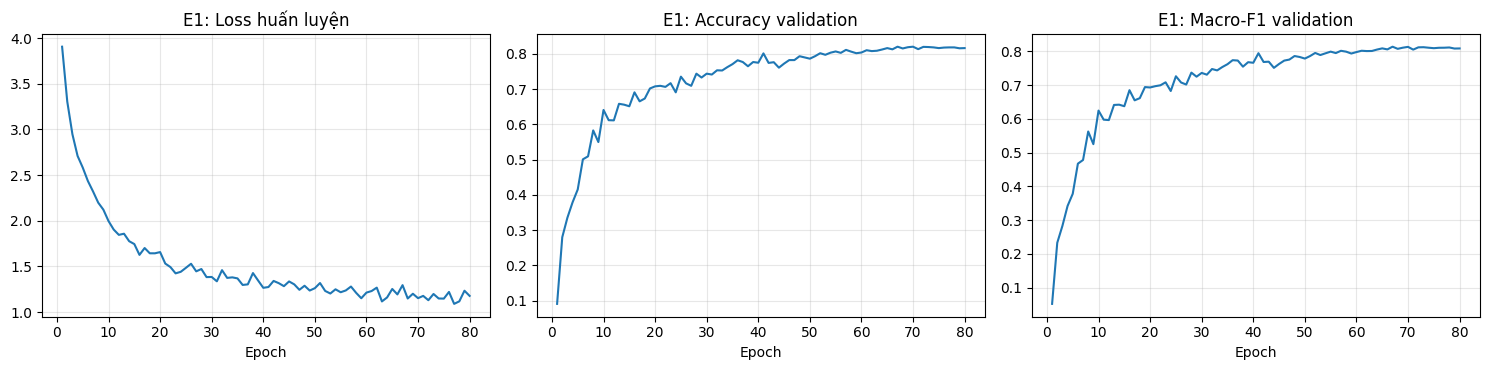

In [11]:
show_exp(EXP_ID)